# Part 3b. TF-IDF

TF-IDF rescales a term count by how rare the term is across reviews. With \(n\) reviews and document frequency \(\mathrm{df}(t)\), scikit-learn's smoothed inverse document frequency is

\[
\mathrm{idf}(t) = \ln\left(\frac{1+n}{1+\mathrm{df}(t)}\right) + 1
\]

\[
\mathrm{tfidf}(t, d) = \mathrm{tf}(t, d) \times \mathrm{idf}(t)
\]

Each review vector is then divided by its Euclidean length. The toy corpus below is calculated with these formulas and checked against `TfidfVectorizer`. The full review corpus uses the same definitions, with English stop-words removed.

## Setup and cleaning

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "tfidf"
OUT = ROOT / "outputs" / "tfidf"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/tfidf
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def clean_text(text):
    text = text.replace("\xa0", " ").lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["review_clean"] = df["Reviews"].map(clean_text)
print("Empty reviews after cleaning:", int((df["review_clean"] == "").sum()))
print("Example:", df.loc[0, "review_clean"][:350])
TOKEN = r"(?u)\b[a-zA-Z]{2,}\b"
VECTOR_KW = dict(stop_words="english", token_pattern=TOKEN, min_df=5, max_df=0.85, max_features=3000)

Empty reviews after cleaning: 0
Example: flight was amazing the crew onboard this flight were very welcoming and gave a good atmosphere the crew serving my aisle goes by the initial g she was very kind helpful gave my mom a bday cake for a late celebration even though it was just a hr min flight seat is well sanitized legroom is spacious ife onboard has many variety of shows music etc bat


## Worked TF-IDF on three short documents

In [4]:
toy_docs = [
    "good food good service flight",
    "poor food rude service flight",
    "good food good crew flight",
]
toy_count = CountVectorizer(token_pattern=TOKEN)
tf_matrix = toy_count.fit_transform(toy_docs).toarray().astype(float)
vocab = np.array(toy_count.get_feature_names_out())
n_docs = tf_matrix.shape[0]
df_t = (tf_matrix > 0).sum(axis=0)
idf = np.log((1 + n_docs) / (1 + df_t)) + 1
tfidf_raw = tf_matrix * idf
tfidf_norm = tfidf_raw / np.linalg.norm(tfidf_raw, axis=1, keepdims=True)

print("Term counts:")
display(pd.DataFrame(tf_matrix, index=["doc1", "doc2", "doc3"], columns=vocab).astype(int))
print("idf = ln((1+n)/(1+df)) + 1, with n = 3:")
display(pd.DataFrame({"df": df_t, "idf": idf}, index=vocab).round(4))
print("L2-normalised TF-IDF:")
display(pd.DataFrame(tfidf_norm, index=["doc1", "doc2", "doc3"], columns=vocab).round(4))

sklearn_tfidf = TfidfVectorizer(token_pattern=TOKEN, norm="l2", smooth_idf=True)
sklearn_matrix = sklearn_tfidf.fit_transform(toy_docs).toarray()
sklearn_terms = list(sklearn_tfidf.get_feature_names_out())
sklearn_matrix = sklearn_matrix[:, [sklearn_terms.index(term) for term in vocab]]
print("Max absolute gap versus TfidfVectorizer:", float(np.max(np.abs(tfidf_norm - sklearn_matrix))))

Term counts:


,crew,flight,food,good,poor,rude,service
doc1,0,1,1,2,0,0,1
doc2,0,1,1,0,1,1,1
doc3,1,1,1,2,0,0,0


idf = ln((1+n)/(1+df)) + 1, with n = 3:


,df,idf
crew,1,1.6931
flight,3,1.0000
food,3,1.0000
good,2,1.2877
poor,1,1.6931
rude,1,1.6931
service,2,1.2877


L2-normalised TF-IDF:


,crew,flight,food,good,poor,rude,service
doc1,0.0000,0.3117,0.3117,0.8028,0.0000,0.0000,0.4014
doc2,0.0000,0.3263,0.3263,0.0000,0.5525,0.5525,0.4202
doc3,0.4993,0.2949,0.2949,0.7595,0.0000,0.0000,0.0000


Max absolute gap versus TfidfVectorizer: 1.1102230246251565e-16


## Full corpus

Same vocabulary for BOW and TF-IDF: True
TF-IDF matrix shape: (8098, 3000)
Sparsity: 98.36%
Highest raw counts in review 4535, with the TF-IDF weight of the same terms:


,term,count,tfidf
0,en,15,0.6199
1,ons,12,0.5268
2,airport,10,0.1550
3,hotel,8,0.1979
4,counter,6,0.1508
5,turkish,4,0.0767
6,pm,4,0.1167
7,lot,4,0.0964
8,met,4,0.1347
9,istanbul,4,0.0729


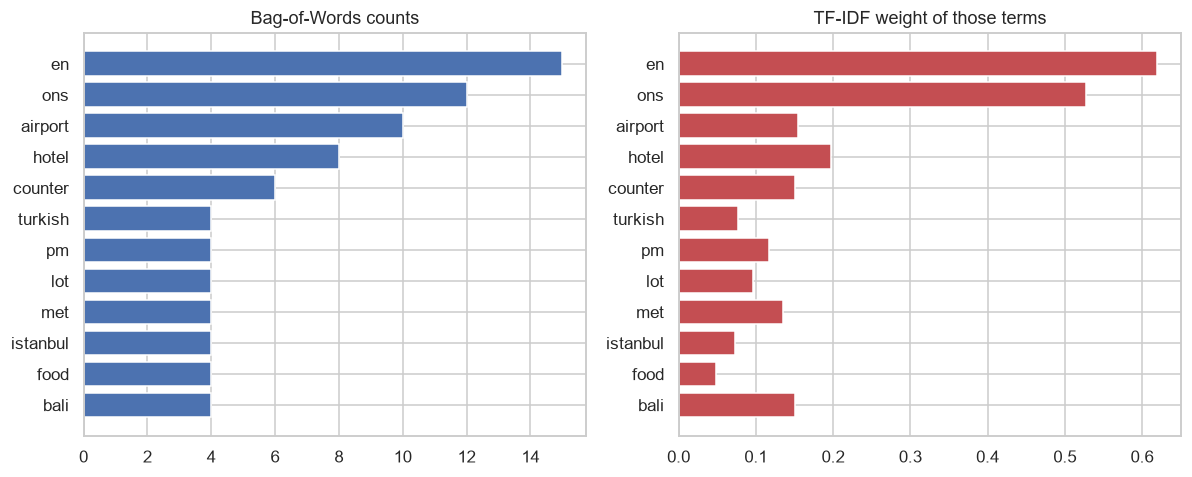

Largest gaps in mean TF-IDF:


,term,yes_minus_no,side
2722,told,-0.0217,higher when not recommended
659,customer,-0.0206,higher when not recommended
2702,ticket,-0.0190,higher when not recommended
2787,turkish,-0.0166,higher when not recommended
1269,hours,-0.0164,higher when not recommended
2301,said,-0.0155,higher when not recommended
2977,worst,-0.0151,higher when not recommended
1575,luggage,-0.0142,higher when not recommended
175,asked,-0.0133,higher when not recommended
1380,istanbul,-0.0132,higher when not recommended


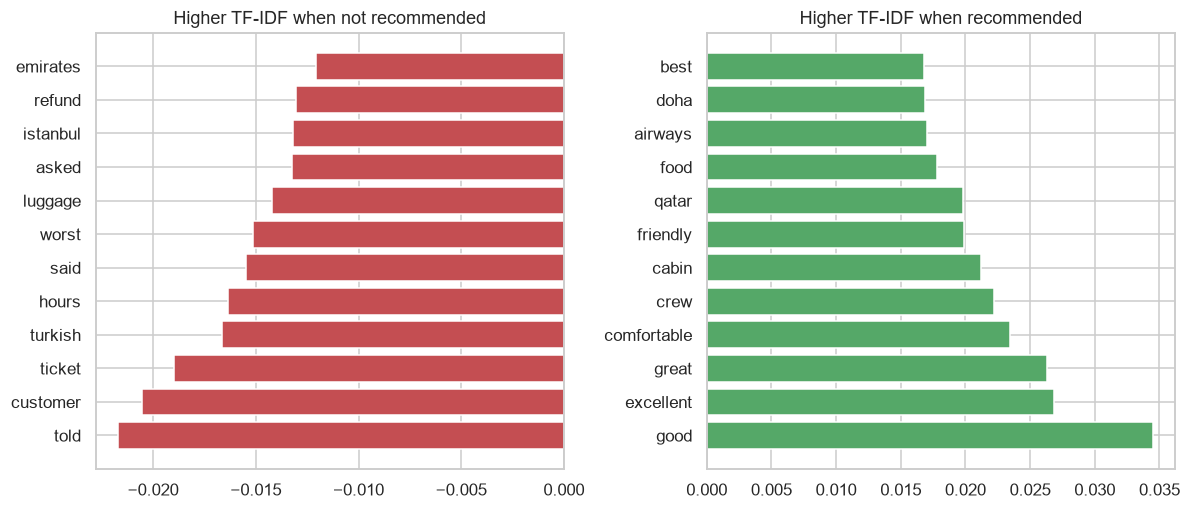

In [5]:
bow = CountVectorizer(**VECTOR_KW)
tfidf_vec = TfidfVectorizer(**VECTOR_KW, norm="l2", smooth_idf=True)
X_bow = bow.fit_transform(df["review_clean"])
X_tfidf = tfidf_vec.fit_transform(df["review_clean"])
terms = np.array(tfidf_vec.get_feature_names_out())
print("Same vocabulary for BOW and TF-IDF:", bow.get_feature_names_out().tolist() == terms.tolist())
print(f"TF-IDF matrix shape: {X_tfidf.shape}")
print(f"Sparsity: {1 - X_tfidf.nnz / np.prod(X_tfidf.shape):.2%}")

doc_i = int(df["review_clean"].str.len().idxmax())
bow_row = np.asarray(X_bow[doc_i].todense()).ravel()
tfidf_row = np.asarray(X_tfidf[doc_i].todense()).ravel()
order = np.argsort(bow_row)[::-1][:12]
side = pd.DataFrame({
    "term": terms[order],
    "count": bow_row[order].astype(int),
    "tfidf": tfidf_row[order],
})
print(f"Highest raw counts in review {doc_i}, with the TF-IDF weight of the same terms:")
display(side.round(4))
side.round(4).to_csv(OUT / "bow_vs_tfidf_one_review.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(side["term"][::-1], side["count"][::-1], color="#4C72B0")
axes[0].set_title("Bag-of-Words counts")
axes[1].barh(side["term"][::-1], side["tfidf"][::-1], color="#C44E52")
axes[1].set_title("TF-IDF weight of those terms")
save_fig(fig, "bow_vs_tfidf.png")

yes_mask = df["Recommended"].str.lower().eq("yes").to_numpy()
diff = np.asarray(X_tfidf[yes_mask].mean(axis=0)).ravel() - np.asarray(X_tfidf[~yes_mask].mean(axis=0)).ravel()
term_diff = pd.DataFrame({"term": terms, "yes_minus_no": diff})
top_pos = term_diff.nlargest(12, "yes_minus_no")
top_neg = term_diff.nsmallest(12, "yes_minus_no").sort_values("yes_minus_no")
term_table = pd.concat([
    top_neg.assign(side="higher when not recommended"),
    top_pos.assign(side="higher when recommended"),
])
term_table.to_csv(OUT / "tfidf_by_recommendation.csv", index=False)
print("Largest gaps in mean TF-IDF:")
display(term_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(top_neg["term"], top_neg["yes_minus_no"], color="#C44E52")
axes[0].set_title("Higher TF-IDF when not recommended")
axes[1].barh(top_pos["term"], top_pos["yes_minus_no"], color="#55A868")
axes[1].set_title("Higher TF-IDF when recommended")
save_fig(fig, "terms_by_recommendation.png")

## Part 3b answer

On the toy corpus, `flight` and `food` sit in every document, so their IDF is the smallest. A word that appears in only one document has a larger IDF. The gap versus `TfidfVectorizer` should be about zero, which confirms the formula. On the real reviews, the side-by-side chart shows a word with a high count receiving a smaller TF-IDF weight when it is common in the corpus. The recommendation chart names the terms whose average TF-IDF differs most between recommended and not-recommended reviews.